In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from os import listdir, makedirs
import pickle

In [2]:
# Data and figure path
DATA_PATH_EXP12 = '/Users/euanprentis/Documents/feat-predict_simulations/exp-12/data'
DATA_PATH_EXP13 = '/Users/euanprentis/Documents/feat-predict_simulations/exp-13/data'
FORMATTED_DATA_PATH_EXP12 = '../data'
FORMATTED_DATA_PATH_EXP13 = '../../exp_13/data'
FIG_PATH = '../figs'
makedirs(FIG_PATH, exist_ok=True)
makedirs(FORMATTED_DATA_PATH_EXP12, exist_ok=True)
makedirs(FORMATTED_DATA_PATH_EXP13, exist_ok=True)

# If overwrite is True, will overwrite existing formatted data
OVERWRITE = False

# Causal depth palettes
DEPTH_PALETTE_BW = sns.cubehelix_palette(4, hue=0, dark=.5, light=.9)

MODEL_PALETTE = {
    'sf': '#D65EB0',
    'mb': '#C0E88F'
}

MODEL_PALETTE_BW = {
    'sf': '#B6B6B6',
    'mb': "#DCDCDC",
    'biased': '0.5'
}

DEPTH_PALETTE_SF = sns.blend_palette(["white", MODEL_PALETTE['sf'], "black"], n_colors=6)[1:-1]
DEPTH_PALETTE_MB = sns.blend_palette(["white", MODEL_PALETTE['mb'], "black"], n_colors=6)[1:-1]

MODEL_LABELS = {
    'sf': 'Successor Features',
    'mb': 'Model-Based'
}

# Load data

In [3]:
def information_from_label(model_label):
    """
    Get field information from model label

    Arguments
    ---------
    model_label : str
        model label
    
    Returns
    -------
    fields : dict
        Dictionary of field information
    """
    fields = {}
    for field in model_label.split('_'):
        if not '-' in field:
            continue
        key, value = field.split('-')
        fields[key] = value
    return fields

def convert_state_str(state_str):
    """
    Convert a string representation of a state to a numpy array.

    Arguments
    ---------
    state_str : str
        The string representation of the state.

    Returns
    -------
    state_arr : numpy.ndarray
        The numpy array representation of the state
    """
    state_str = state_str.replace('[ ', '[').replace('  ', ' ')
    state_str = state_str[1:-1]
    state_str = state_str.split(' ')
    state_arr = np.array(state_str, dtype=int)
    return state_arr

def load_from_dir(data_path, phase):
    """
    Load behavioral data for a given phase

    Arguments
    ---------
    data_path : str
        Path to the data directory
    phase : str
        The phase of the data to load

    Returns
    -------
    df : pandas.DataFrame
        The loaded data
    """
    df = []
    for env_label in listdir(data_path):
        if env_label[0] == '.':
            continue
        env_path = f'{data_path}/{env_label}'
        for model_label in listdir(env_path):
            if model_label[0] == '.':
                continue
            model_path = f'{env_path}/{model_label}'
            for sub_label in listdir(model_path):
                if sub_label[0] == '.':
                    continue
                phase_path = f'{model_path}/{sub_label}/{phase}'
                for f in listdir(phase_path):
                    if '.csv' in f:
                        this_df = pd.read_csv(
                            f'{phase_path}/{f}'
                        )
                        env_info = information_from_label(env_label)
                        for key, value in env_info.items():
                            this_df[key] = value
                        this_df['env_label'] = env_label
                        df.append(this_df)
    df = pd.concat(df)
    return df

def get_target_frequency(
        df,
        grouping_vars = [],
        state = 'target',
        binary_coding = True
        ):
    """
    Get the frequency of each target state within a group

    Arguments
    ---------
    df : pandas.DataFrame
        Behavioral data frame
    grouping_vars : list
        List of columns to group by
    state : str
        The state column to analyze
    binary_coding : bool
        Whether to use binary coding for the frequency column

    Returns
    -------
    df : pandas.DataFrame
        Data frame with added frequency column
    """

    # Create labels for the count, rate, and frequency columns
    count_label = f'count_{state}'
    rate_label = f'rate_{state}'
    freq_label = f'freq_{state}'

    # Get rates of each target per model and id
    target_counts = df.groupby(
        [*grouping_vars, state]
        ).size().reset_index(name=count_label)
    total_counts = target_counts.groupby(
        grouping_vars
        )[count_label].transform('sum')
    target_counts[rate_label] = target_counts[count_label]/total_counts

    # Find the highest and lowest rates per id and model
    highest_rate = target_counts.groupby(
        grouping_vars
        )[rate_label].transform('max')

    # Categorize each item
    if binary_coding:
        target_counts[freq_label] = target_counts[rate_label] == highest_rate
        target_counts[freq_label] = target_counts[freq_label].astype(int)
    df = pd.merge(
        df,
        target_counts,
    )

    return df

def count_causal(row, return_proportion=True):
    """
    Count the proportion (default) or number of possible causal
    inferences on a trial.

    Arguments
    ---------
    row : pandas.Series
        A row of the behavioral data frame
    return_proportion : bool
        Whether to return as proportion (True) or count (False)
    
    Returns
    -------
    n_causal : float
        The proportion/number of possible causal inferences
    """
    is_causal = row['options_comb_arr'] & row['target_comb_arr']
    n_causal = np.sum(is_causal)
    if return_proportion:
        n_causal = n_causal/row['dim']
    return n_causal

def count_spurious(row, clusters):
    """
    Count the proportion of spurious transitions on a trial.

    Arguments
    ---------
    row : pandas.Series
        A row of the behavioral data frame
    clusters : dict
        A dictionary of feature clusters for each dimension

    Returns
    -------
    p_spurious : float
        The proportion of spurious transitions
    """

    # No spurious transitions in one-dimensional environments
    if row['dim'] == 1:
        return 0  
    
    # Count causal transitions
    n_causal = count_causal(row, return_proportion=False)
    
    # Arrays represent the two clusters of feature combinations
    cluster = clusters[row['dim']]

    # Count total transitions within each cluster
    n_transitions = np.sum([
        np.prod([
            np.sum(row['options_comb_arr'].astype(bool) & cluster),
            np.sum(row['target_comb_arr'].astype(bool) & cluster)
        ]),
        np.prod([
            np.sum(row['options_comb_arr'].astype(bool) & ~cluster),
            np.sum(row['target_comb_arr'].astype(bool) & ~cluster)
        ])
    ])

    # Proportion of spurious transitions
    n_spurious = n_transitions - n_causal
    p_spurious = n_spurious/(row['dim']**2 - row['dim'])
    
    return p_spurious

def get_transition_proportions(df):
    """
    Get the proportion of causal and spurious transitions on each trial

    Arguments
    ---------
    df : pandas.DataFrame
        Behavioral data frame

    Returns
    -------
    df : pandas.DataFrame
        Behavioral data frame with added columns for p_causal and
        p_spurious
    """

    # Convert strings to arrays
    df['options_comb_arr'] = df['options_comb'].apply(convert_state_str)
    df['target_comb_arr'] = df['target_comb'].apply(convert_state_str)

    # Initialize transition proportion columns
    df['p_spurious'] = 0
    df['p_causal'] = 0

    # Compute p_causal
    df['p_causal'] = df.apply(count_causal, axis=1)

    # Define feature arrays for dim=2 and dim=4
    clusters = {
        2: np.array([1, 1, 0, 0], dtype=bool),
        4: np.array([1, 1, 1, 1, 0, 0, 0, 0], dtype=bool)
    }

    # Apply only where dim is 2 or 4
    idx = df['dim'] > 1
    df.loc[idx, 'p_spurious'] = df.loc[idx].apply(
        count_spurious,
        args = (clusters,),
        axis = 1
    )

    # Drop array columns
    df = df.drop(columns=['options_comb_arr', 'target_comb'])

    return df

def create_mask(n_features, n_categories=4):

    n_features_per_category = n_features/n_categories
    mask = np.repeat(
        np.repeat(
            np.eye(n_categories),
            n_features_per_category,
            axis = 1
        ),
        n_features_per_category,
        axis = 0
    )
    mask = mask - np.eye(len(mask))
    return mask


## Load training

In [4]:
# Load existing formatted data frame if it exists
training_fname = f'{FORMATTED_DATA_PATH_EXP12}/training_df.csv'
if ('training_df.csv' in listdir(FORMATTED_DATA_PATH_EXP12)) and not OVERWRITE:
    training_exp12_df = pd.read_csv(training_fname)

# Otherwise, load the data from the raw data
else:
    # Load all training data into one directory
    training_df = load_from_dir(DATA_PATH_EXP12, 'training')

    # Format columns
    training_df['depth'] = training_df['depth'].astype(int)
    training_df['dim'] = training_df['dim'].astype(int)

    # Label target frequency
    training_df = get_target_frequency(
        training_df,
        grouping_vars = ['id', 'env_label', 'model_label']
    )

    # Label composition frequency
    training_df = get_target_frequency(
        training_df,
        grouping_vars = ['id', 'env_label', 'model_label'],
        state = 'composition',
        binary_coding = False
    )

    # Select columns
    training_df = training_df[[
        'id',
        'alpha',
        'env_label',
        'model_label',
        'depth',
        'dim',
        'trial',
        'options_comb',
        'target',
        'composition',
        'freq_target',
        'rate_composition',
        'p',
        'reward'
    ]]

    # Proportion of possible reward earned on each trial
    training_df['p_reward'] = training_df['reward']/training_df['dim']

    # Save the formatted data
    training_df.to_csv(training_fname, index=False)

    training_exp12_df = training_df.copy()

training_exp12_df['model_class'] = 'sf'

training_exp12_df

,id,alpha,env_label,model_label,depth,dim,trial,options_comb,target,composition,freq_target,rate_composition,p,reward,p_reward,model_class
0,161,0.940674,depth-4_dim-2,ss,4,2,1,[1 1 0 0],[10 1 0 0],[6 5 0 0],1,0.153704,0.250000,2,1.0,sf
1,161,0.940674,depth-4_dim-2,ss,4,2,2,[1 1 0 0],[ 1 10 0 0],[5 5 0 0],1,0.096296,0.250000,1,0.5,sf
2,161,0.940674,depth-4_dim-2,ss,4,2,3,[0 0 1 1],[ 0 0 10 10],[0 0 5 6],0,0.142593,0.250000,1,0.5,sf
3,161,0.940674,depth-4_dim-2,ss,4,2,4,[0 0 1 1],[ 0 0 10 1],[0 0 5 5],1,0.100000,0.250000,1,0.5,sf
4,161,0.940674,depth-4_dim-2,ss,4,2,5,[0 0 1 1],[ 0 0 1 10],[0 0 5 6],1,0.142593,0.239146,2,1.0,sf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4319995,187,0.420041,depth-3_dim-1,ss,3,1,2156,[0 1 0 0],[0 1 0 0],[0 5 0 0],1,0.128704,0.306082,0,0.0,sf
4319996,187,0.420041,depth-3_dim-1,ss,3,1,2157,[0 1 0 0],[0 8 0 0],[0 5 0 0],1,0.128704,0.693918,1,1.0,sf
4319997,187,0.420041,depth-3_dim-1,ss,3,1,2158,[0 1 0 0],[0 8 0 0],[0 4 0 0],1,0.121296,0.306082,0,0.0,sf
4319998,187,0.420041,depth-3_dim-1,ss,3,1,2159,[0 0 1 0],[0 0 8 0],[0 0 5 0],1,0.122685,0.693918,1,1.0,sf


In [5]:
# Load existing formatted data frame if it exists
training_fname = f'{FORMATTED_DATA_PATH_EXP13}/training_df.csv'
if ('training_df.csv' in listdir(FORMATTED_DATA_PATH_EXP13)) and not OVERWRITE:
    training_exp13_df = pd.read_csv(training_fname)

# Otherwise, load the data from the raw data
else:
    # Load all training data into one directory
    training_df = load_from_dir(DATA_PATH_EXP13, 'training')

    # Format columns
    training_df['depth'] = training_df['depth'].astype(int)
    training_df['dim'] = training_df['dim'].astype(int)

    # Label target frequency
    training_df = get_target_frequency(
        training_df,
        grouping_vars = ['id', 'env_label', 'model_label']
    )

    # Label composition frequency
    training_df = get_target_frequency(
        training_df,
        grouping_vars = ['id', 'env_label', 'model_label'],
        state = 'composition',
        binary_coding = False
    )

    # Select columns
    training_df = training_df[[
        'id',
        'alpha',
        'env_label',
        'model_label',
        'depth',
        'dim',
        'trial',
        'options_comb',
        'target',
        'composition',
        'freq_target',
        'rate_composition',
        'p',
        'reward'
    ]]

    # Proportion of possible reward earned on each trial
    training_df['p_reward'] = training_df['reward']/training_df['dim']

    # Save the formatted data
    training_df.to_csv(training_fname, index=False)

    training_exp13_df = training_df.copy()


training_exp13_df['model_class'] = 'mb'

training_exp13_df

,id,alpha,env_label,model_label,depth,dim,trial,options_comb,target,composition,freq_target,rate_composition,p,reward,p_reward,model_class
0,161,0.940674,depth-4_dim-2,ss,4,2,1,[1 1 0 0],[10 1 0 0],[6 5 0 0],1,0.155556,0.250000,2,1.0,mb
1,161,0.940674,depth-4_dim-2,ss,4,2,2,[1 1 0 0],[ 1 10 0 0],[6 5 0 0],1,0.155556,0.878949,0,0.0,mb
2,161,0.940674,depth-4_dim-2,ss,4,2,3,[0 0 1 1],[ 0 0 10 10],[0 0 5 6],0,0.139815,0.250000,1,0.5,mb
3,161,0.940674,depth-4_dim-2,ss,4,2,4,[0 0 1 1],[ 0 0 10 1],[0 0 5 6],1,0.139815,0.856414,0,0.0,mb
4,161,0.940674,depth-4_dim-2,ss,4,2,5,[0 0 1 1],[ 0 0 1 10],[0 0 5 6],1,0.139815,0.451566,2,1.0,mb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4319995,187,0.420041,depth-3_dim-1,ss,3,1,2156,[0 1 0 0],[0 1 0 0],[0 5 0 0],1,0.127778,0.306082,0,0.0,mb
4319996,187,0.420041,depth-3_dim-1,ss,3,1,2157,[0 1 0 0],[0 8 0 0],[0 5 0 0],1,0.127778,0.693918,1,1.0,mb
4319997,187,0.420041,depth-3_dim-1,ss,3,1,2158,[0 1 0 0],[0 8 0 0],[0 4 0 0],1,0.122222,0.306082,0,0.0,mb
4319998,187,0.420041,depth-3_dim-1,ss,3,1,2159,[0 0 1 0],[0 0 8 0],[0 0 5 0],1,0.123611,0.693918,1,1.0,mb


In [6]:
training_df = pd.concat([training_exp12_df, training_exp13_df], axis=0)
training_df

,id,alpha,env_label,model_label,depth,dim,trial,options_comb,target,composition,freq_target,rate_composition,p,reward,p_reward,model_class
0,161,0.940674,depth-4_dim-2,ss,4,2,1,[1 1 0 0],[10 1 0 0],[6 5 0 0],1,0.153704,0.250000,2,1.0,sf
1,161,0.940674,depth-4_dim-2,ss,4,2,2,[1 1 0 0],[ 1 10 0 0],[5 5 0 0],1,0.096296,0.250000,1,0.5,sf
2,161,0.940674,depth-4_dim-2,ss,4,2,3,[0 0 1 1],[ 0 0 10 10],[0 0 5 6],0,0.142593,0.250000,1,0.5,sf
3,161,0.940674,depth-4_dim-2,ss,4,2,4,[0 0 1 1],[ 0 0 10 1],[0 0 5 5],1,0.100000,0.250000,1,0.5,sf
4,161,0.940674,depth-4_dim-2,ss,4,2,5,[0 0 1 1],[ 0 0 1 10],[0 0 5 6],1,0.142593,0.239146,2,1.0,sf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4319995,187,0.420041,depth-3_dim-1,ss,3,1,2156,[0 1 0 0],[0 1 0 0],[0 5 0 0],1,0.127778,0.306082,0,0.0,mb
4319996,187,0.420041,depth-3_dim-1,ss,3,1,2157,[0 1 0 0],[0 8 0 0],[0 5 0 0],1,0.127778,0.693918,1,1.0,mb
4319997,187,0.420041,depth-3_dim-1,ss,3,1,2158,[0 1 0 0],[0 8 0 0],[0 4 0 0],1,0.122222,0.306082,0,0.0,mb
4319998,187,0.420041,depth-3_dim-1,ss,3,1,2159,[0 0 1 0],[0 0 8 0],[0 0 5 0],1,0.123611,0.693918,1,1.0,mb


## Load test

In [7]:
# Load existing formatted data frame if it exists
test_fname = f'{FORMATTED_DATA_PATH_EXP12}/test_df.csv'
if ('test_df.csv' in listdir(FORMATTED_DATA_PATH_EXP12)) and not OVERWRITE:
    test_exp12_df = pd.read_csv(test_fname)

# Otherwise, load the data from the raw data
else:

    # Load all test data into one directory
    test_df = load_from_dir(DATA_PATH_EXP12, 'test')

    # Format columns
    test_df['depth'] = test_df['depth'].astype(int)
    test_df['dim'] = test_df['dim'].astype(int)

    # Label test targets/options as old (from training) or new
    for env_label in test_df['env_label'].unique():

        # Get targets and options seen during training
        idx = training_df['env_label'] == env_label
        training_targets = np.unique(training_df.loc[idx, 'target'])
        training_options = np.unique(training_df.loc[idx, 'options_comb'])

        # Label test targets and options as old or novel
        idx = test_df['env_label'] == env_label
        test_df.loc[idx, 'novel_target'] = np.isin(
            test_df.loc[idx, 'target'],
            training_targets,
            invert = True
        ).astype(int)
        test_df.loc[idx, 'novel_options'] = np.isin(
            test_df.loc[idx, 'options_comb'],
            training_options,
            invert = True
        ).astype(int)

    # Get trials where options and target features match
    test_df['options_target_comb_match'] = (
        test_df['options_comb'] == test_df['target_comb']
    ).astype(int)

    # Label test trials that would have been seen during training
    test_df['old'] = (
        np.logical_not(test_df['novel_target']) &
        np.logical_not(test_df['novel_options']) &
        test_df['options_target_comb_match']
    ).astype(int)

    # Label frequent old targets
    test_df = pd.merge(
        test_df,
        training_df[['id', 'env_label', 'target', 'freq_target']].drop_duplicates(),
        on=['id', 'env_label', 'target'],
        how='left'
    )
    idx = np.isnan(test_df['freq_target'])
    test_df.loc[idx, 'freq_target'] = -1

    # Select columns
    test_df = test_df[[
        'id',
        'alpha',
        'model_label',
        'depth',
        'dim',
        'options_comb',
        'target_comb',
        'target',
        'novel_target',
        'novel_options',
        'old',
        'freq_target',
        'reward'
    ]]

    # Get causal and spurious transition propostions
    test_df = get_transition_proportions(test_df)

    # Proportion of possible reward earned on each trial
    test_df['p_reward'] = (test_df['reward']/test_df['dim'])/(test_df['p_causal'])

    # Save the formatted data
    test_df.to_csv(test_fname, index=False)

    test_exp12_df = test_df.copy()

test_exp12_df['model_class'] = 'sf'

test_exp12_df

,id,alpha,model_label,depth,dim,options_comb,target,novel_target,novel_options,old,freq_target,reward,target_comb_arr,p_spurious,p_causal,p_reward,model_class
0,150,0.908584,ss,4,2,[1 1 0 0],[0 0 1 1],0.0,0.0,0,0.0,0,[0 0 1 1],0.0,0.0,NaN,sf
1,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 1 10],0.0,0.0,0,1.0,0,[0 0 1 1],0.0,0.0,NaN,sf
2,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 10 1],0.0,0.0,0,1.0,0,[0 0 1 1],0.0,0.0,NaN,sf
3,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 10 10],0.0,0.0,0,0.0,0,[0 0 1 1],0.0,0.0,NaN,sf
4,150,0.908584,ss,4,2,[1 1 0 0],[0 1 0 1],1.0,0.0,0,-1.0,0,[0 1 0 1],0.5,0.5,0.0,sf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319995,149,0.881308,ss,3,1,[0 0 0 1],[0 0 8 0],0.0,0.0,0,1.0,0,[0 0 1 0],0.0,0.0,NaN,sf
319996,149,0.881308,ss,3,1,[0 0 0 1],[0 1 0 0],0.0,0.0,0,1.0,0,[0 1 0 0],0.0,0.0,NaN,sf
319997,149,0.881308,ss,3,1,[0 0 0 1],[0 8 0 0],0.0,0.0,0,1.0,0,[0 1 0 0],0.0,0.0,NaN,sf
319998,149,0.881308,ss,3,1,[0 0 0 1],[1 0 0 0],0.0,0.0,0,1.0,0,[1 0 0 0],0.0,0.0,NaN,sf


In [8]:
# Load existing formatted data frame if it exists
test_fname = f'{FORMATTED_DATA_PATH_EXP13}/test_df.csv'
if ('test_df.csv' in listdir(FORMATTED_DATA_PATH_EXP13)) and not OVERWRITE:
    test_exp13_df = pd.read_csv(test_fname)

# Otherwise, load the data from the raw data
else:

    # Load all test data into one directory
    test_df = load_from_dir(DATA_PATH_EXP13, 'test')

    # Format columns
    test_df['depth'] = test_df['depth'].astype(int)
    test_df['dim'] = test_df['dim'].astype(int)

    # Label test targets/options as old (from training) or new
    for env_label in test_df['env_label'].unique():

        # Get targets and options seen during training
        idx = training_df['env_label'] == env_label
        training_targets = np.unique(training_df.loc[idx, 'target'])
        training_options = np.unique(training_df.loc[idx, 'options_comb'])

        # Label test targets and options as old or novel
        idx = test_df['env_label'] == env_label
        test_df.loc[idx, 'novel_target'] = np.isin(
            test_df.loc[idx, 'target'],
            training_targets,
            invert = True
        ).astype(int)
        test_df.loc[idx, 'novel_options'] = np.isin(
            test_df.loc[idx, 'options_comb'],
            training_options,
            invert = True
        ).astype(int)

    # Get trials where options and target features match
    test_df['options_target_comb_match'] = (
        test_df['options_comb'] == test_df['target_comb']
    ).astype(int)

    # Label test trials that would have been seen during training
    test_df['old'] = (
        np.logical_not(test_df['novel_target']) &
        np.logical_not(test_df['novel_options']) &
        test_df['options_target_comb_match']
    ).astype(int)

    # Label frequent old targets
    test_df = pd.merge(
        test_df,
        training_df[['id', 'env_label', 'target', 'freq_target']].drop_duplicates(),
        on=['id', 'env_label', 'target'],
        how='left'
    )
    idx = np.isnan(test_df['freq_target'])
    test_df.loc[idx, 'freq_target'] = -1

    # Select columns
    test_df = test_df[[
        'id',
        'alpha',
        'model_label',
        'depth',
        'dim',
        'options_comb',
        'target_comb',
        'target',
        'novel_target',
        'novel_options',
        'old',
        'freq_target',
        'reward'
    ]]

    # Get causal and spurious transition propostions
    test_df = get_transition_proportions(test_df)

    # Proportion of possible reward earned on each trial
    test_df['p_reward'] = (test_df['reward']/test_df['dim'])/(test_df['p_causal'])

    # Save the formatted data
    test_df.to_csv(test_fname, index=False)

    test_exp13_df = test_df.copy()

test_exp13_df['model_class'] = 'mb'

test_exp13_df

,id,alpha,model_label,depth,dim,options_comb,target,novel_target,novel_options,old,freq_target,reward,target_comb_arr,p_spurious,p_causal,p_reward,model_class
0,150,0.908584,ss,4,2,[1 1 0 0],[0 0 1 1],0.0,0.0,0,0.0,0,[0 0 1 1],0.0,0.0,NaN,mb
1,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 1 10],0.0,0.0,0,1.0,0,[0 0 1 1],0.0,0.0,NaN,mb
2,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 10 1],0.0,0.0,0,1.0,0,[0 0 1 1],0.0,0.0,NaN,mb
3,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 10 10],0.0,0.0,0,0.0,0,[0 0 1 1],0.0,0.0,NaN,mb
4,150,0.908584,ss,4,2,[1 1 0 0],[0 1 0 1],1.0,0.0,0,-1.0,0,[0 1 0 1],0.5,0.5,0.0,mb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319995,149,0.881308,ss,3,1,[0 0 0 1],[0 0 8 0],0.0,0.0,0,1.0,0,[0 0 1 0],0.0,0.0,NaN,mb
319996,149,0.881308,ss,3,1,[0 0 0 1],[0 1 0 0],0.0,0.0,0,1.0,0,[0 1 0 0],0.0,0.0,NaN,mb
319997,149,0.881308,ss,3,1,[0 0 0 1],[0 8 0 0],0.0,0.0,0,1.0,0,[0 1 0 0],0.0,0.0,NaN,mb
319998,149,0.881308,ss,3,1,[0 0 0 1],[1 0 0 0],0.0,0.0,0,1.0,0,[1 0 0 0],0.0,0.0,NaN,mb


In [9]:
test_df = pd.concat([test_exp12_df, test_exp13_df], axis=0)
test_df

,id,alpha,model_label,depth,dim,options_comb,target,novel_target,novel_options,old,freq_target,reward,target_comb_arr,p_spurious,p_causal,p_reward,model_class
0,150,0.908584,ss,4,2,[1 1 0 0],[0 0 1 1],0.0,0.0,0,0.0,0,[0 0 1 1],0.0,0.0,NaN,sf
1,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 1 10],0.0,0.0,0,1.0,0,[0 0 1 1],0.0,0.0,NaN,sf
2,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 10 1],0.0,0.0,0,1.0,0,[0 0 1 1],0.0,0.0,NaN,sf
3,150,0.908584,ss,4,2,[1 1 0 0],[ 0 0 10 10],0.0,0.0,0,0.0,0,[0 0 1 1],0.0,0.0,NaN,sf
4,150,0.908584,ss,4,2,[1 1 0 0],[0 1 0 1],1.0,0.0,0,-1.0,0,[0 1 0 1],0.5,0.5,0.0,sf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
319995,149,0.881308,ss,3,1,[0 0 0 1],[0 0 8 0],0.0,0.0,0,1.0,0,[0 0 1 0],0.0,0.0,NaN,mb
319996,149,0.881308,ss,3,1,[0 0 0 1],[0 1 0 0],0.0,0.0,0,1.0,0,[0 1 0 0],0.0,0.0,NaN,mb
319997,149,0.881308,ss,3,1,[0 0 0 1],[0 8 0 0],0.0,0.0,0,1.0,0,[0 1 0 0],0.0,0.0,NaN,mb
319998,149,0.881308,ss,3,1,[0 0 0 1],[1 0 0 0],0.0,0.0,0,1.0,0,[1 0 0 0],0.0,0.0,NaN,mb


In [10]:
grouping_variables = [
    'depth',
    'dim',
    'id',
    'model_class',
    'model_label',
    'alpha',
    'old',
    'novel_target',
    'novel_options',
    'freq_target',
    'p_causal',
    'p_spurious'
]
test_summary = test_df[[*grouping_variables, 'reward']]
test_summary = test_summary.groupby(grouping_variables)
test_summary = test_summary.mean()
test_summary = test_summary.reset_index()
test_summary['p_reward'] = test_summary['reward']/(test_summary['p_causal']*test_summary['dim'])
test_summary

,depth,dim,id,model_class,model_label,alpha,old,novel_target,novel_options,freq_target,p_causal,p_spurious,reward,p_reward
0,1,1,1,mb,ss,0.417022,0,0.0,0.0,1.0,0.0,0.0,0.0000,NaN
1,1,1,1,mb,ss,0.417022,1,0.0,0.0,1.0,1.0,0.0,0.7500,0.75000
2,1,1,1,sf,ss,0.417022,0,0.0,0.0,1.0,0.0,0.0,0.0000,NaN
3,1,1,1,sf,ss,0.417022,1,0.0,0.0,1.0,1.0,0.0,0.7500,0.75000
4,1,1,2,mb,ss,0.435995,0,0.0,0.0,1.0,0.0,0.0,0.0000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43995,4,2,250,sf,ss-sampler,0.214779,0,1.0,1.0,-1.0,0.0,1.0,0.0000,NaN
43996,4,2,250,sf,ss-sampler,0.214779,0,1.0,1.0,-1.0,0.5,0.5,0.8125,0.81250
43997,4,2,250,sf,ss-sampler,0.214779,0,1.0,1.0,-1.0,1.0,0.0,1.5625,0.78125
43998,4,2,250,sf,ss-sampler,0.214779,1,0.0,0.0,0.0,1.0,1.0,1.7500,0.87500


## Subject information

In [11]:
subj_df = test_summary[['id', 'model_class', 'model_label', 'alpha']]
subj_df = subj_df.drop_duplicates()
subj_df = subj_df.reset_index(drop=True)
subj_df

,id,model_class,model_label,alpha
0,1,mb,ss,0.417022
1,1,sf,ss,0.417022
2,2,mb,ss,0.435995
3,2,sf,ss,0.435995
4,3,mb,ss,0.550798
...,...,...,...,...
995,248,sf,ss-sampler,0.691987
996,249,mb,ss-sampler,0.516937
997,249,sf,ss-sampler,0.516937
998,250,mb,ss-sampler,0.214779


## Load Representations

In [12]:
def convert_states_to_labels(states):
    """
    Convert array of states to string labels

    Arguments
    ---------
    states : np.ndarray
        Array represent states by their features

    Returns
    -------
    labels : list
        state labels
    """
    labels = [''.join(label) for label in states.astype(str)]
    return labels

def standardize_reps_order(reps):
    """
    Standardize the order of representations

    Arguments
    ---------
    reps : dict
        representation dictionary

    Returns
    -------
    reps : dict
        standardized representation dictionary
    """
    
    # Get indices for standardized ordering
    idx_sorted_S = np.lexsort(reps['S'].T[::-1])
    idx_sorted_F = np.lexsort(reps['F_raw'].T[::-1])
    S = reps['S'][idx_sorted_S]
    F_raw = reps['F_raw'][idx_sorted_F]

    # Re-order rows by whether starts are conjunctive or not
    conjunctive_starts = False
    if 'conjunctive_starts' in reps['agent_info']:
        if reps['agent_info']['conjunctive_starts']:
            conjunctive_starts = True
    if conjunctive_starts:
            M = reps['M'][idx_sorted_S]
            bias = reps['bias'][idx_sorted_S]
            row_labels = convert_states_to_labels(S)
    else:
        M = reps['M'][idx_sorted_F]
        bias = reps['bias'][idx_sorted_F]
        row_labels = convert_states_to_labels(F_raw)

    # Re-order columns by whether successors are conjunctive or not
    conjunctive_successors = False
    if 'conjunctive_successors' in reps['agent_info']:
        if reps['agent_info']['conjunctive_successors']:
            conjunctive_successors = True
    if conjunctive_successors:
        M = M.T[idx_sorted_S].T
        bias = bias.T[idx_sorted_S].T
        col_labels = convert_states_to_labels(S)
    else:
        M = M.T[idx_sorted_F].T
        bias = bias.T[idx_sorted_F].T
        col_labels = convert_states_to_labels(F_raw)

    # Assign re-ordered representations
    reps['S'] = S
    reps['F_raw'] = F_raw
    reps['M'] = M
    reps['bias'] = bias
    reps['row_labels'] = row_labels
    reps['col_labels'] = col_labels

    return reps

def get_label_matrix(features):
    """
    Get a label matrix that reflects every conjunction of features

    Arguments
    ---------
    features : np.ndarray
        Array of features

    Returns
    -------
    label_matrix : np.ndarray
        Label matrix
    """
    n_features = len(features)
    label_matrix = np.zeros((n_features, n_features), dtype=object)
    for i, feature_i in enumerate(features):
        for j, feature_j in enumerate(features[i:], start=i):

            # Cannot have a conjunction of features from one category
            cat_i = feature_i.astype(bool)
            cat_j = feature_j.astype(bool)
            same_category = np.all(cat_i == cat_j)
            if same_category:
                label = 'None'

            # Conjunction of features from different categories
            else:
                label = str(feature_i + feature_j)

            # Assign labels to the matrix
            label_matrix[i, j] = label
            label_matrix[j, i] = label
    return label_matrix

def load_representations(data_path):
    """
    Load successor matrices and label matrices

    Arguments
    ---------
    data_path : str
        Path to the data directory
    
    Returns
    -------
    representations : dict
        Dictionary of successor matrices
    label_matrices : dict
        Dictionary of label matrices
    """
    representations = {}
    label_matrices = {}
    for env_label in listdir(data_path):
        if env_label[0] == '.':
            continue
        dim = int(information_from_label(env_label)['dim'])
        depth = int(information_from_label(env_label)['depth'])
        env_path = f'{data_path}/{env_label}'
        for model_label in listdir(env_path):
            if model_label[0] == '.':
                continue
            model_path = f'{env_path}/{model_label}'
            for sub_label in listdir(model_path):
                if sub_label[0] == '.':
                    continue
                reps_path = f'{model_path}/{sub_label}/representations'
                for fname in listdir(reps_path):
                    if '.pkl' not in fname:
                        continue
                    agent_id = int(fname.replace('.pkl', '').split('_')[1])
                    key = (dim, depth, sub_label, agent_id)
                    with open(f'{reps_path}/{fname}', 'rb') as f:

                        # Load representations in a standardized order
                        reps = standardize_reps_order(pickle.load(f))

                        # Extract successor matrix
                        representations[key] = reps['M']

                        # Extract label matrix 
                        label_matrices[key] = get_label_matrix(reps['F_raw'])

    return representations, label_matrices

In [13]:
representations, label_matrices = {}, {}
representations['sf'], label_matrices['sf'] = load_representations(DATA_PATH_EXP12)
representations['mb'], label_matrices['mb'] = load_representations(DATA_PATH_EXP13)

# Analyze Behavior

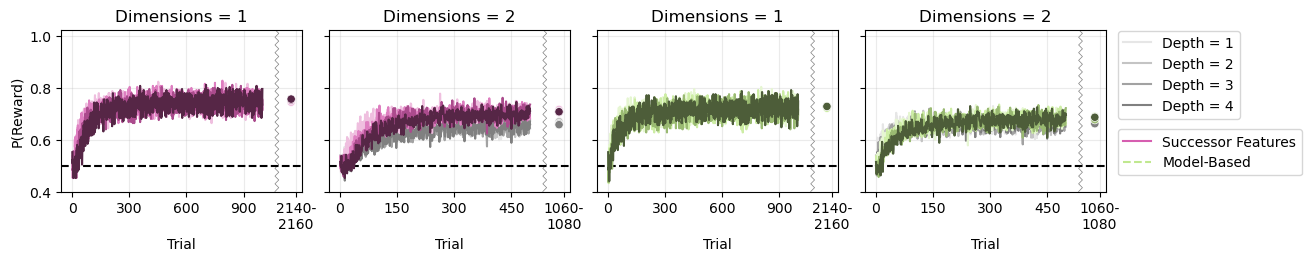

In [14]:
fig, axs = plt.subplots(1, 4, figsize=(13, 2.5), constrained_layout=True)

for i, model_class in enumerate(['sf', 'mb']):

    if model_class == 'sf':
        depth_palette = DEPTH_PALETTE_SF
    else:
        depth_palette = DEPTH_PALETTE_MB

    model_idx = training_df['model_class'] == model_class

    #######################################################################
    ### Dim = 1 ###########################################################
    #######################################################################
    ax = axs[i*2]
    ax.grid(True, alpha=0.25)
    ax.axhline(.5, c='k', ls='--')

    # Plot learning curves for trials < 1000
    idx = model_idx & (training_df['dim'] == 1) & (training_df['trial'] < 1000)
    sns.lineplot(
        data = training_df.loc[idx],
        x = 'trial',
        y = 'p_reward',
        hue = 'depth',
        palette = depth_palette,
        errorbar = None,
        ax = ax
    )

    # Final trial performance after learning has converged
    idx = model_idx & training_df['dim'] == 1
    final_trial = np.max(training_df.loc[idx, 'trial'])
    idx = idx & (training_df['trial'] > final_trial - 20)
    final_trial_df = training_df.loc[idx, ['depth', 'trial', 'p_reward']]
    final_trial_df['trial'] = 1200 - 50
    final_trial_df = final_trial_df.groupby(['depth', 'trial']).mean().reset_index()
    sns.scatterplot(
        data = final_trial_df,
        x = 'trial',  
        y = 'p_reward',
        hue = 'depth',
        palette = depth_palette,
        ax = ax
    )

    # Format
    ax.set_title('Dimensions = 1')
    ax.set_xlabel('Trial')
    if i == 0:
        ax.set_ylabel('P(Reward)')
    else:
        ax.set_yticklabels([])
        ax.set_ylabel(None)
    ax.get_legend().remove()
    ax.set_ylim(.4, 1.025)
    ax.set_xticks(
        [0, 300, 600, 900, 1200 - 25],
        ['0', '300', '600', '900', f'{final_trial - 20}-\n{final_trial}']
        )
    ax.plot(
        [1090 - 25, 1110 - 25]*24,
        np.linspace(.4, 1.1, 24*2),
        c = '.5',
        lw = .5,
        zorder = 0
        )


    #######################################################################
    ### Dim = 2 ###########################################################
    #######################################################################
    ax = axs[1 + i*2]
    ax.grid(True, alpha=0.25)
    ax.axhline(.5, c='k', ls='--')

    # Plot learning curves for causal learner for trials < 500
    idx = (
        model_idx &
        (training_df['dim'] == 2) &
        (training_df['model_label'] == 'ss-sampler') &
        (training_df['trial'] < 500)
    )
    sns.lineplot(
        data = training_df.loc[idx],
        x = 'trial',
        y = 'p_reward',
        hue = 'depth',
        palette = DEPTH_PALETTE_BW,
        errorbar = None,
        ax = ax
    )

    # Final trial performance after learning has converged
    idx = (
        model_idx &
        (training_df['dim'] == 2) &
        (training_df['model_label'] == 'ss-sampler') 
    )
    final_trial = np.max(training_df.loc[idx, 'trial'])
    idx = idx & (training_df['trial'] > final_trial - 20)
    final_trial_df = training_df.loc[idx, ['depth', 'trial', 'p_reward']]
    final_trial_df['trial'] = 600 - 25
    final_trial_df = final_trial_df.groupby(['depth', 'trial']).mean().reset_index()
    sns.scatterplot(
        data = final_trial_df,
        x = 'trial',  
        y = 'p_reward',
        hue = 'depth',
        palette = DEPTH_PALETTE_BW,
        ax = ax
    )


    # Plot learning curves for regular learner for trials < 500
    idx = (
        model_idx &
        (training_df['dim'] == 2) &
        (training_df['model_label'] == 'ss') &
        (training_df['trial'] < 500)
    )
    sns.lineplot(
        data = training_df.loc[idx],
        x = 'trial',
        y = 'p_reward',
        hue = 'depth',
        palette = depth_palette,
        errorbar = None,
        ax = ax
    )

    # Final trial performance after learning has converged
    idx = (
        model_idx & 
        (training_df['dim'] == 2) &
        (training_df['model_label'] == 'ss') 
    )
    final_trial = np.max(training_df.loc[idx, 'trial'])
    idx = idx & (training_df['trial']  > final_trial - 20)
    final_trial_df = training_df.loc[idx, ['depth', 'trial', 'p_reward']]
    final_trial_df['trial'] = 600 - 25
    final_trial_df = final_trial_df.groupby(['depth', 'trial']).mean().reset_index()
    sns.scatterplot(
        data = final_trial_df,
        x = 'trial',  
        y = 'p_reward',
        hue = 'depth',
        palette = depth_palette,
        ax = ax
    )

    # Format
    ax.set_title('Dimensions = 2')
    ax.set_xlabel('Trial')
    ax.set_ylabel(None)
    ax.set_yticklabels([])
    ax.set_ylim(.4, 1.025)
    ax.set_xticks(
        [0, 150, 300, 450, 600 - 25/2],
        ['0', '150', '300', '450', f'{final_trial - 20}-\n{final_trial}']
        )
    ax.plot(
        [545 - 25/2, 555 - 25/2]*24,
        np.linspace(.4, 1.1, 24*2),
        c = '.5',
        lw = .5,
        zorder = 0
        )


    if i == 1:

        # Depth legend
        handles = ax.get_legend_handles_labels()[0]
        depth_legend = ax.legend(
            handles = handles[:4],
            labels = ['Depth = 1', 'Depth = 2', 'Depth = 3', 'Depth = 4'],
            loc = (1.05, .45)
        )
        ax.add_artist(depth_legend)
        colors = {'Label A': 'blue', 'Label B': 'red'}

        # Model class legend
        legend_handles = [
            Line2D(
                [0], [0],
                color = MODEL_PALETTE['sf'],
                label = MODEL_LABELS['sf'],
                linestyle = '-'
                ),
            Line2D(
                [0], [0],
                color = MODEL_PALETTE['mb'],
                label = MODEL_LABELS['mb'],
                linestyle = '--'
                )
            ]
        ax.legend(
            handles = legend_handles,
            loc = (1.05, .1)
        )
    else:
        ax.get_legend().remove()

fig.savefig(f'{FIG_PATH}/convergence_all.pdf', dpi=300, bbox_inches='tight')

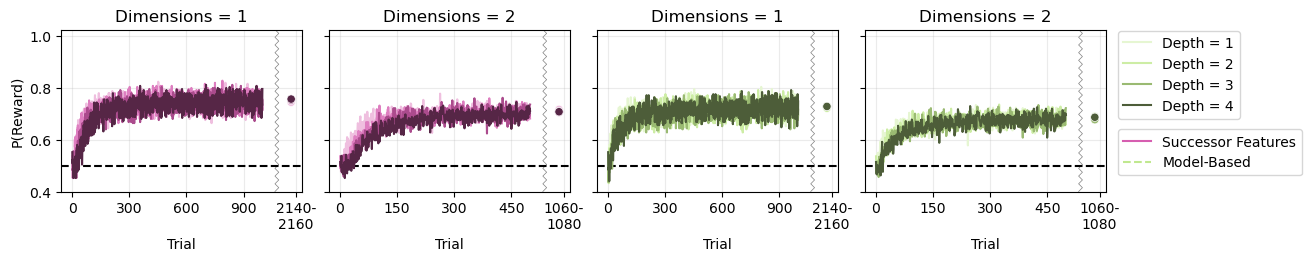

In [17]:
fig, axs = plt.subplots(1, 4, figsize=(13, 2.5), constrained_layout=True)

for i, model_class in enumerate(['sf', 'mb']):

    if model_class == 'sf':
        depth_palette = DEPTH_PALETTE_SF
    else:
        depth_palette = DEPTH_PALETTE_MB

    model_idx = training_df['model_class'] == model_class

    #######################################################################
    ### Dim = 1 ###########################################################
    #######################################################################
    ax = axs[i*2]
    ax.grid(True, alpha=0.25)
    ax.axhline(.5, c='k', ls='--')

    # Plot learning curves for trials < 1000
    idx = model_idx & (training_df['dim'] == 1) & (training_df['trial'] < 1000)
    sns.lineplot(
        data = training_df.loc[idx],
        x = 'trial',
        y = 'p_reward',
        hue = 'depth',
        palette = depth_palette,
        errorbar = None,
        ax = ax
    )

    # Final trial performance after learning has converged
    idx = model_idx & training_df['dim'] == 1
    final_trial = np.max(training_df.loc[idx, 'trial'])
    idx = idx & (training_df['trial'] > final_trial - 20)
    final_trial_df = training_df.loc[idx, ['depth', 'trial', 'p_reward']]
    final_trial_df['trial'] = 1200 - 50
    final_trial_df = final_trial_df.groupby(['depth', 'trial']).mean().reset_index()
    sns.scatterplot(
        data = final_trial_df,
        x = 'trial',  
        y = 'p_reward',
        hue = 'depth',
        palette = depth_palette,
        ax = ax
    )

    # Format
    ax.set_title('Dimensions = 1')
    ax.set_xlabel('Trial')
    if i == 0:
        ax.set_ylabel('P(Reward)')
    else:
        ax.set_yticklabels([])
        ax.set_ylabel(None)
    ax.get_legend().remove()
    ax.set_ylim(.4, 1.025)
    ax.set_xticks(
        [0, 300, 600, 900, 1200 - 25],
        ['0', '300', '600', '900', f'{final_trial - 20}-\n{final_trial}']
        )
    ax.plot(
        [1090 - 25, 1110 - 25]*24,
        np.linspace(.4, 1.1, 24*2),
        c = '.5',
        lw = .5,
        zorder = 0
        )


    #######################################################################
    ### Dim = 2 ###########################################################
    #######################################################################
    ax = axs[1 + i*2]
    ax.grid(True, alpha=0.25)
    ax.axhline(.5, c='k', ls='--')

    # # Plot learning curves for causal learner for trials < 500
    # idx = (
    #     model_idx &
    #     (training_df['dim'] == 2) &
    #     (training_df['model_label'] == 'ss-sampler') &
    #     (training_df['trial'] < 500)
    # )
    # sns.lineplot(
    #     data = training_df.loc[idx],
    #     x = 'trial',
    #     y = 'p_reward',
    #     hue = 'depth',
    #     palette = DEPTH_PALETTE_BW,
    #     errorbar = None,
    #     ax = ax
    # )

    # # Final trial performance after learning has converged
    # idx = (
    #     model_idx &
    #     (training_df['dim'] == 2) &
    #     (training_df['model_label'] == 'ss-sampler') 
    # )
    # final_trial = np.max(training_df.loc[idx, 'trial'])
    # idx = idx & (training_df['trial'] > final_trial - 20)
    # final_trial_df = training_df.loc[idx, ['depth', 'trial', 'p_reward']]
    # final_trial_df['trial'] = 600 - 25
    # final_trial_df = final_trial_df.groupby(['depth', 'trial']).mean().reset_index()
    # sns.scatterplot(
    #     data = final_trial_df,
    #     x = 'trial',  
    #     y = 'p_reward',
    #     hue = 'depth',
    #     palette = DEPTH_PALETTE_BW,
    #     ax = ax
    # )


    # Plot learning curves for regular learner for trials < 500
    idx = (
        model_idx &
        (training_df['dim'] == 2) &
        (training_df['model_label'] == 'ss') &
        (training_df['trial'] < 500)
    )
    sns.lineplot(
        data = training_df.loc[idx],
        x = 'trial',
        y = 'p_reward',
        hue = 'depth',
        palette = depth_palette,
        errorbar = None,
        ax = ax
    )

    # Final trial performance after learning has converged
    idx = (
        model_idx & 
        (training_df['dim'] == 2) &
        (training_df['model_label'] == 'ss') 
    )
    final_trial = np.max(training_df.loc[idx, 'trial'])
    idx = idx & (training_df['trial']  > final_trial - 20)
    final_trial_df = training_df.loc[idx, ['depth', 'trial', 'p_reward']]
    final_trial_df['trial'] = 600 - 25
    final_trial_df = final_trial_df.groupby(['depth', 'trial']).mean().reset_index()
    sns.scatterplot(
        data = final_trial_df,
        x = 'trial',  
        y = 'p_reward',
        hue = 'depth',
        palette = depth_palette,
        ax = ax
    )

    # Format
    ax.set_title('Dimensions = 2')
    ax.set_xlabel('Trial')
    ax.set_ylabel(None)
    ax.set_yticklabels([])
    ax.set_ylim(.4, 1.025)
    ax.set_xticks(
        [0, 150, 300, 450, 600 - 25/2],
        ['0', '150', '300', '450', f'{final_trial - 20}-\n{final_trial}']
        )
    ax.plot(
        [545 - 25/2, 555 - 25/2]*24,
        np.linspace(.4, 1.1, 24*2),
        c = '.5',
        lw = .5,
        zorder = 0
        )


    if i == 1:

        # Depth legend
        handles = ax.get_legend_handles_labels()[0]
        depth_legend = ax.legend(
            handles = handles[:4],
            labels = ['Depth = 1', 'Depth = 2', 'Depth = 3', 'Depth = 4'],
            loc = (1.05, .45)
        )
        ax.add_artist(depth_legend)
        colors = {'Label A': 'blue', 'Label B': 'red'}

        # Model class legend
        legend_handles = [
            Line2D(
                [0], [0],
                color = MODEL_PALETTE['sf'],
                label = MODEL_LABELS['sf'],
                linestyle = '-'
                ),
            Line2D(
                [0], [0],
                color = MODEL_PALETTE['mb'],
                label = MODEL_LABELS['mb'],
                linestyle = '--'
                )
            ]
        ax.legend(
            handles = legend_handles,
            loc = (1.05, .1)
        )
    else:
        ax.get_legend().remove()

fig.savefig(f'{FIG_PATH}/convergence_no-sampler.pdf', dpi=300, bbox_inches='tight')

## Frequency sensitivity in test inference

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_25462/2105211202.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Infreq.', 'Freq.'])


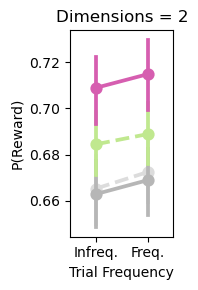

In [15]:
fig, ax = plt.subplots(figsize=(2.5, 3))

# Plot Dim 2 with spurious learning
idx = (
    (test_summary['dim'] == 2) &
    (test_summary['model_label'] == 'ss') &
    (test_summary['old'] == 1)
)
sns.pointplot(
    data = test_summary.loc[idx],
    x = 'freq_target',
    y = 'p_reward',
    hue = 'model_class',
    linestyles = ['--', '-'],
    palette = MODEL_PALETTE,
    ax = ax
)

# Plot Dim 2 no spurious learning
idx = (
    (test_summary['dim'] == 2) &
    (test_summary['model_label'] == 'ss-sampler') &
    (test_summary['old'] == 1)
)
sns.pointplot(
    data = test_summary.loc[idx],
    x = 'freq_target',
    y = 'p_reward',
    hue = 'model_class',
    linestyles = ['--', '-'],
    palette = MODEL_PALETTE_BW,
    zorder = 0,
    ax = ax
)

ax.set_title('Dimensions = 2')
ax.set_xlabel('Trial Frequency')
ax.set_ylabel('P(Reward)')
ax.set_xticklabels(['Infreq.', 'Freq.'])
ax.get_legend().remove()

ax.set_box_aspect(2)
fig.tight_layout()

fig.savefig(f'{FIG_PATH}/test-freq-dim2-all.pdf', dpi=300)

## Generalization to novel options

/var/folders/d9/5q7mq_bn55x0t3cnmcd02v1w0000gn/T/ipykernel_25462/1943006231.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Old', 'Novel'])


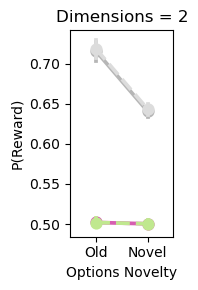

In [16]:
fig, ax = plt.subplots(figsize=(2.5, 3))

# Plot Dim 2 with spurious learning
idx = (
    (test_summary['dim'] == 2) &
    (test_summary['model_label'] == 'ss') &
    (test_summary['p_causal'] == .5) &
    (test_summary['p_spurious'] == .5) 
)
sns.pointplot(
    data = test_summary.loc[idx],
    x = 'novel_options',
    y = 'p_reward',
    hue = 'model_class',
    hue_order = ['sf', 'mb'],
    linestyles = ['-', '--'],
    palette = MODEL_PALETTE,
    ax = ax
)

# Plot Dim 2 no spurious learning
idx = (
    (test_summary['dim'] == 2) &
    (test_summary['model_label'] == 'ss-sampler') &
    (test_summary['p_causal'] == .5) &
    (test_summary['p_spurious'] == .5) 
)
sns.pointplot(
    data = test_summary.loc[idx],
    x = 'novel_options',
    y = 'p_reward',
    hue = 'model_class',
    hue_order = ['sf', 'mb'],
    linestyles = ['-', '--'],
    palette = MODEL_PALETTE_BW,
    zorder = 0,
    ax = ax
)

ax.set_title('Dimensions = 2')
ax.set_xlabel('Options Novelty')
ax.set_ylabel('P(Reward)')
ax.set_xticklabels(['Old', 'Novel'])
ax.get_legend().remove()

ax.set_box_aspect(2)
fig.tight_layout()

fig.savefig(f'{FIG_PATH}/test-opsnov-dim2-all.pdf', dpi=300)